In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 1. Muat data
url = "https://docs.google.com/spreadsheets/d/1g6e5BYsXnUS1yJCcblcHAJXaawVdHMexeuh7mLREbcw/export?format=csv"
df = pd.read_csv(url)

In [ ]:
# 2. Pemeriksaan awal
print(df.shape)
print(df.isna().sum())
print("Duplikat:", df.duplicated().sum())
df = df.drop_duplicates()

(9994, 21)
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplikat: 0


In [ ]:
# 3. Ubah tipe tanggal dan buat kolom waktu
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"]  = pd.to_datetime(df["Ship Date"])
df["Year"]  = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M")
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

In [ ]:
# 4. Growth revenue bulanan dan tahunan
monthly = df.groupby("Month")["Sales"].sum().reset_index()
monthly["Growth_%"] = monthly["Sales"].pct_change() * 100

yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Revenue_Growth_%"] = yearly["Sales"].pct_change() * 100
print(yearly.round(2))

          Sales    Profit  Revenue_Growth_%
Year                                       
2014  484247.50  49543.97               NaN
2015  470532.51  61618.60             -2.83
2016  609205.60  81795.17             29.47
2017  733215.26  93439.27             20.36


In [ ]:
# 5. Margin per kategori dan sub-kategori
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat["Margin_%"] = cat["Profit"] / cat["Sales"] * 100
print(cat.round(2))

                     Sales     Profit  Margin_%
Category                                       
Furniture        741999.80   18451.27      2.49
Office Supplies  719047.03  122490.80     17.04
Technology       836154.03  145454.95     17.40


In [ ]:
# 6. Pengaruh diskon: kelompokkan ke dalam level
df["Discount Level"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1.0],
    labels=["0%", "1-20%", "21-40%", ">40%"],
)
disc = df.groupby("Discount Level", observed=True).agg(
    transaksi=("Profit", "size"),
    rata_profit=("Profit", "mean"),
    total_profit=("Profit", "sum"),
)
print(disc.round(2))

                transaksi  rata_profit  total_profit
Discount Level                                      
0%                   4798        66.90     320987.60
1-20%                3803        26.50     100785.47
21-40%                460       -77.86     -35817.47
>40%                  933      -106.71     -99558.59


In [ ]:
# 7. Nilai pelanggan (revenue, profit, frekuensi order)
cust = df.groupby("Customer Name").agg(
    revenue=("Sales", "sum"),
    profit=("Profit", "sum"),
    orders=("Order ID", "nunique"),
).sort_values("revenue", ascending=False)
print(cust.head(10).round(2))

                     revenue   profit  orders
Customer Name                                
Sean Miller         25043.05 -1980.74       5
Tamara Chand        19052.22  8981.32       5
Raymond Buch        15117.34  6976.10       6
Tom Ashbrook        14595.62  4703.79       4
Adrian Barton       14473.57  5444.81      10
Ken Lonsdale        14175.23   806.86      12
Sanjit Chand        14142.33  5757.41       9
Hunter Lopez        12873.30  5622.43       6
Sanjit Engle        12209.44  2650.68      11
Christopher Conant  12129.07  2177.05       5


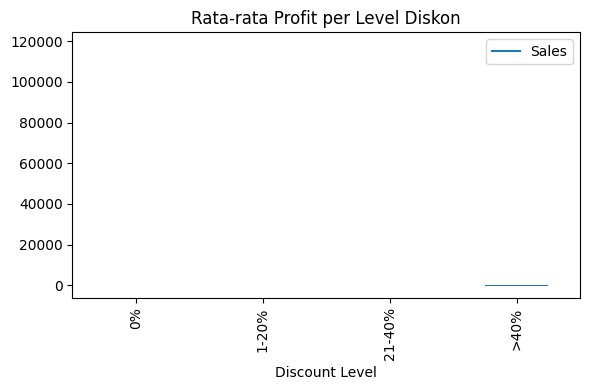

In [ ]:
# 8. Visualisasi
monthly.plot(x="Month", y="Sales", figsize=(10, 4), title="Revenue Bulanan")
plt.tight_layout(); plt.savefig("revenue_bulanan.png", dpi=150)

disc["rata_profit"].plot(kind="bar", figsize=(6, 4),
                         title="Rata-rata Profit per Level Diskon")
plt.tight_layout(); plt.savefig("diskon_vs_profit.png", dpi=150)

In [ ]:
# 9. Ekspor data bersih untuk Excel, Power BI, dan Tableau
df.to_csv("superstore_clean.csv", index=False)